In [1]:
from pathlib import Path

DATA_PATH = Path("../data/raw")

files = list(DATA_PATH.rglob("*"))

print("Total files:", sum(f.is_file() for f in files))

for file in files[:15]:
    print(file.name)

Total files: 57
00000_ring1_processed.pkl
00000_ring2_processed.pkl
00001_ring1_processed.pkl
00001_ring2_processed.pkl
00002_ring1_processed.pkl
00002_ring2_processed.pkl
00003_ring1_processed.pkl
00003_ring2_processed.pkl
00004_ring1_processed.pkl
00004_ring2_processed.pkl
00005_ring1_processed.pkl
00005_ring2_processed.pkl
00006_ring1_processed.pkl
00006_ring2_processed.pkl
00007_ring1_processed.pkl


In [2]:
from pathlib import Path
import os

DATA_PATH = Path("../data/raw")

files = [f for f in DATA_PATH.rglob("*") if f.is_file()]

print("Total files:", len(files))
print("\nFirst 20 files:")

for file in files[:20]:
    print(file.name)

Total files: 57

First 20 files:
00000_ring1_processed.pkl
00000_ring2_processed.pkl
00001_ring1_processed.pkl
00001_ring2_processed.pkl
00002_ring1_processed.pkl
00002_ring2_processed.pkl
00003_ring1_processed.pkl
00003_ring2_processed.pkl
00004_ring1_processed.pkl
00004_ring2_processed.pkl
00005_ring1_processed.pkl
00005_ring2_processed.pkl
00006_ring1_processed.pkl
00006_ring2_processed.pkl
00007_ring1_processed.pkl
00007_ring2_processed.pkl
00008_ring1_processed.pkl
00008_ring2_processed.pkl
00009_ring1_processed.pkl
00009_ring2_processed.pkl


In [3]:
import re
from collections import Counter

pattern = re.compile(r"(\d+)_ring(\d+)_processed\.pkl")

records = []

for file in files:
    match = pattern.fullmatch(file.name)

    if match:
        records.append({
            "participant": match.group(1),
            "ring": match.group(2),
            "filename": file.name
        })

participants = sorted(set(r["participant"] for r in records))

print("Total valid files:", len(records))
print("Unique participants:", len(participants))
print("Ring distribution:", Counter(r["ring"] for r in records))

print("\nParticipant IDs:")
print(participants)

print("\nFiles not matching expected pattern:")
print([f.name for f in files if f.is_file() and not pattern.fullmatch(f.name)])

Total valid files: 57
Unique participants: 29
Ring distribution: Counter({'2': 29, '1': 28})

Participant IDs:
['00000', '00001', '00002', '00003', '00004', '00005', '00006', '00007', '00008', '00009', '00010', '00011', '00012', '00013', '00014', '00015', '00016', '00017', '00018', '00019', '00020', '00021', '00022', '00023', '00024', '00025', '00026', '00028', '00029']

Files not matching expected pattern:
[]


In [4]:
import pandas as pd

sample_file = DATA_PATH / "00000_ring1_processed.pkl"

df = pd.read_pickle(sample_file)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (38, 62)

First 5 rows:


,id,start,end,fs,ir-raw,ir-standardized,ir-filtered,ir-difference,ir-welch,ir-filtered-rr,...,bvp_nn50,bvp_pnn50,resp_rr,spo2,samsung_hr,oura_hr,BP_sys,BP_dia,Experiment,Label
0,0,1.742608e+09,1.742608e+09,100.049454,"[11594342, 11594584, 11594531, 11594842, 11594...","[-2.686629215916888, -2.649086951112538, -2.65...","[-0.10921155420375905, -0.1300626285788523, -0...","[-0.42444935343208445, -0.43750796391441493, -...","[0.006919994403562041, 0.006959652293537309, 0...","[-0.5344537257927322, -0.5339553502251715, -0....",...,4,10.526316,9.089016,96.0,None,None,101.0,66.0,Health,sitting
1,1,1.742608e+09,1.742608e+09,100.322885,"[11605502, 11605957, 11605662, 11606182, 11606...","[-0.12370948721350479, -0.04007644249062736, -...","[0.16523947762857713, 0.20030895393853645, 0.2...","[0.7217725592150511, 0.7588308880398004, 0.801...","[0.004363056183950917, 0.00438683673939567, 0....","[0.5414462019234472, 0.5517753427990363, 0.561...",...,8,20.512821,13.635623,95.8,None,None,101.0,66.0,Health,sitting
2,2,1.742608e+09,1.742608e+09,100.338132,"[11607065, 11607407, 11607830, 11608185, 11608...","[-1.7532930790324515, -1.7402170668856132, -1....","[0.038914156753336905, 0.04785760469993646, 0....","[0.9902381932969184, 1.0114276444525163, 1.032...","[0.00026719309292289165, 0.0002688902319845638...","[-0.4004153614057831, -0.4005859063981271, -0....",...,20,45.454545,10.72377,96.6,None,None,None,None,Health,sitting
3,3,1.742608e+09,1.742608e+09,100.333500,"[11629158, 11629886, 11630195, 11630394, 11630...","[0.30840340780079356, 0.37648664190412595, 0.4...","[-0.006117646829130609, 0.029311477589772705, ...","[1.4269782536002382, 1.376173691743236, 1.2834...","[0.0018095333380965073, 0.0018202109419359804,...","[-0.1703024824998958, -0.17700208592774044, -0...",...,5,12.5,12.019393,96.8,None,None,None,None,Health,sitting
4,4,1.742608e+09,1.742608e+09,100.341803,"[11639397, 11639876, 11639766, 11640060, 11640...","[1.6895295931402343, 1.7510348419378425, 1.736...","[-0.06789471301578659, -0.04860960678744631, -...","[0.5694426139800682, 0.5246830831025832, 0.444...","[0.0026379503374199227, 0.0026561988231560574,...","[-0.26898305705606584, -0.2819789450488749, -0...",...,4,10.0,12.178545,96.233333,None,None,None,None,Health,sitting



Column names:
['id', 'start', 'end', 'fs', 'ir-raw', 'ir-standardized', 'ir-filtered', 'ir-difference', 'ir-welch', 'ir-filtered-rr', 'ir-difference-rr', 'ir-welch-rr', 'ir-quality', 'red-raw', 'red-standardized', 'red-filtered', 'red-difference', 'red-welch', 'red-filtered-rr', 'red-difference-rr', 'red-welch-rr', 'red-quality', 'ax-raw', 'ax-standardized', 'ax-filtered', 'ax-difference', 'ax-welch', 'ax-filtered-rr', 'ax-difference-rr', 'ax-welch-rr', 'ay-raw', 'ay-standardized', 'ay-filtered', 'ay-difference', 'ay-welch', 'ay-filtered-rr', 'ay-difference-rr', 'ay-welch-rr', 'az-raw', 'az-standardized', 'az-filtered', 'az-difference', 'az-welch', 'az-filtered-rr', 'az-difference-rr', 'az-welch-rr', 'bvp', 'resp', 'hr', 'bvp_hr', 'bvp_sdnn', 'bvp_rmssd', 'bvp_nn50', 'bvp_pnn50', 'resp_rr', 'spo2', 'samsung_hr', 'oura_hr', 'BP_sys', 'BP_dia', 'Experiment', 'Label']

Data types:
id              int64
start         float64
end           float64
fs            float64
ir-raw         objec

In [5]:
print("COLUMN NAME AND DATA TYPE")
print("-" * 50)

for col in df.columns:
    print(f"{col:30} {df[col].dtype}")

COLUMN NAME AND DATA TYPE
--------------------------------------------------
id                             int64
start                          float64
end                            float64
fs                             float64
ir-raw                         object
ir-standardized                object
ir-filtered                    object
ir-difference                  object
ir-welch                       object
ir-filtered-rr                 object
ir-difference-rr               object
ir-welch-rr                    object
ir-quality                     float64
red-raw                        object
red-standardized               object
red-filtered                   object
red-difference                 object
red-welch                      object
red-filtered-rr                object
red-difference-rr              object
red-welch-rr                   object
red-quality                    float64
ax-raw                         object
ax-standardized                object
ax-filt

In [6]:
from collections import Counter

object_columns = df.select_dtypes(include="object").columns

for col in object_columns:
    value = df[col].dropna()

    if len(value) > 0:
        first_value = value.iloc[0]

        print(f"\nColumn: {col}")
        print("Python type:", type(first_value))
        print("Sample value:", str(first_value)[:150])


Column: ir-raw
Python type: <class 'numpy.ndarray'>
Sample value: [11594342 11594584 11594531 ... 11605635 11605580 11605502]

Column: ir-standardized
Python type: <class 'numpy.ndarray'>
Sample value: [-2.68662922 -2.64908695 -2.65730902 ... -0.93470857 -0.9432409
 -0.9553413 ]

Column: ir-filtered
Python type: <class 'numpy.ndarray'>
Sample value: [-0.10921155 -0.13006263 -0.15155521 ...  0.09190971  0.08574286
  0.07866013]

Column: ir-difference
Python type: <class 'numpy.ndarray'>
Sample value: [-0.42444935 -0.43750796 -0.4479771  ... -0.12553393 -0.14417771
  0.        ]

Column: ir-welch
Python type: <class 'numpy.ndarray'>
Sample value: [0.00691999 0.00695965 0.00699931 ... 0.00398181 0.00391039 0.00383897]

Column: ir-filtered-rr
Python type: <class 'numpy.ndarray'>
Sample value: [-5.34453726e-01 -5.33955350e-01 -5.33331164e-01 ... -2.45743917e-04
 -2.04532927e-04 -1.68749671e-04]

Column: ir-difference-rr
Python type: <class 'numpy.ndarray'>
Sample value: [0.13544668 0.16963

In [7]:

print("NUMERICAL COLUMNS:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nOBJECT COLUMNS:")
print(df.select_dtypes(include="object").columns.tolist())

print("\nUNIQUE EXPERIMENTS:")
print(df["Experiment"].unique())

print("\nUNIQUE ACTIVITY LABELS:")
print(df["Label"].unique())


NUMERICAL COLUMNS:
['id', 'start', 'end', 'fs', 'ir-quality', 'red-quality']

OBJECT COLUMNS:
['ir-raw', 'ir-standardized', 'ir-filtered', 'ir-difference', 'ir-welch', 'ir-filtered-rr', 'ir-difference-rr', 'ir-welch-rr', 'red-raw', 'red-standardized', 'red-filtered', 'red-difference', 'red-welch', 'red-filtered-rr', 'red-difference-rr', 'red-welch-rr', 'ax-raw', 'ax-standardized', 'ax-filtered', 'ax-difference', 'ax-welch', 'ax-filtered-rr', 'ax-difference-rr', 'ax-welch-rr', 'ay-raw', 'ay-standardized', 'ay-filtered', 'ay-difference', 'ay-welch', 'ay-filtered-rr', 'ay-difference-rr', 'ay-welch-rr', 'az-raw', 'az-standardized', 'az-filtered', 'az-difference', 'az-welch', 'az-filtered-rr', 'az-difference-rr', 'az-welch-rr', 'bvp', 'resp', 'hr', 'bvp_hr', 'bvp_sdnn', 'bvp_rmssd', 'bvp_nn50', 'bvp_pnn50', 'resp_rr', 'spo2', 'samsung_hr', 'oura_hr', 'BP_sys', 'BP_dia', 'Experiment', 'Label']

UNIQUE EXPERIMENTS:
['Health']

UNIQUE ACTIVITY LABELS:
['sitting' 'spo2']


In [8]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

display(
    missing_df[missing_df["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

,Missing_Count,Missing_Percentage
BP_sys,35,92.11
BP_dia,35,92.11
oura_hr,34,89.47
samsung_hr,33,86.84


In [9]:
# Check the rows where BP measurements are available

print("Rows with BP_sys:")
display(df[df["BP_sys"].notna()][
    ["id", "BP_sys", "BP_dia", "Experiment", "Label"]
])

print("\nActivity label counts:")
print(df["Label"].value_counts(dropna=False))

print("\nMissing values by column:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

Rows with BP_sys:


,id,BP_sys,BP_dia,Experiment,Label
0,0,101.0,66.0,Health,sitting
1,1,101.0,66.0,Health,sitting
37,37,109.0,65.0,Health,spo2



Activity label counts:
Label
sitting    20
spo2       18
Name: count, dtype: int64

Missing values by column:
BP_dia              35
BP_sys              35
oura_hr             34
samsung_hr          33
id                   0
az-raw               0
az-welch             0
az-difference        0
az-filtered          0
az-standardized      0
ay-filtered-rr       0
ay-welch-rr          0
ay-difference-rr     0
az-difference-rr     0
ay-welch             0
dtype: int64


In [10]:
columns_to_check = [
    "hr", "bvp_hr", "resp_rr", "spo2",
    "samsung_hr", "oura_hr", "BP_sys", "BP_dia"
]

for col in columns_to_check:
    print(f"\n{col}")
    print("Python types:", df[col].dropna().map(
        lambda x: type(x).__name__
    ).value_counts().to_dict())
    print("Sample values:", df[col].dropna().head(5).tolist())


hr
Python types: {'float': 38}
Sample values: [80.63333333333334, 79.4, 78.0, 81.96666666666667, 81.53333333333333]

bvp_hr
Python types: {'float64': 38}
Sample values: [78.87560674697167, 79.58205986936481, 81.02337412496577, 82.97866878299685, 84.40380585332446]

resp_rr
Python types: {'float64': 38}
Sample values: [9.089015848785461, 13.635623066953961, 10.72376992637641, 12.019392962416863, 12.178544580860702]

spo2
Python types: {'float': 38}
Sample values: [96.0, 95.8, 96.6, 96.8, 96.23333333333333]

samsung_hr
Python types: {'float64': 5}
Sample values: [84.0, 86.0, 86.0, 91.0, 91.0]

oura_hr
Python types: {'float64': 4}
Sample values: [83.0, 83.0, 83.0, 83.0]

BP_sys
Python types: {'float64': 3}
Sample values: [101.0, 101.0, 109.0]

BP_dia
Python types: {'float64': 3}
Sample values: [66.0, 66.0, 65.0]


In [11]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,38.0,NaN,NaN,NaN,18.5,11.113055,0.0,9.25,18.5,27.75,37.0
start,38.0,NaN,NaN,NaN,1742608785.074241,387.153531,1742608173.130203,1742608450.626187,1742608728.131021,1742609125.630544,1742609403.131628
end,38.0,NaN,NaN,NaN,1742608814.972261,387.123756,1742608203.125369,1742608480.628771,1742608758.132689,1742609155.632096,1742609433.13076
fs,38.0,NaN,NaN,NaN,100.326053,0.098321,100.046416,100.318332,100.33423,100.338419,100.669613
ir-raw,38,38,"[11594342, 11594584, 11594531, 11594842, 11594...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
oura_hr,4.0,1.0,83.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BP_sys,3.0,2.0,101.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BP_dia,3.0,2.0,66.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Experiment,38,1,Health,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN


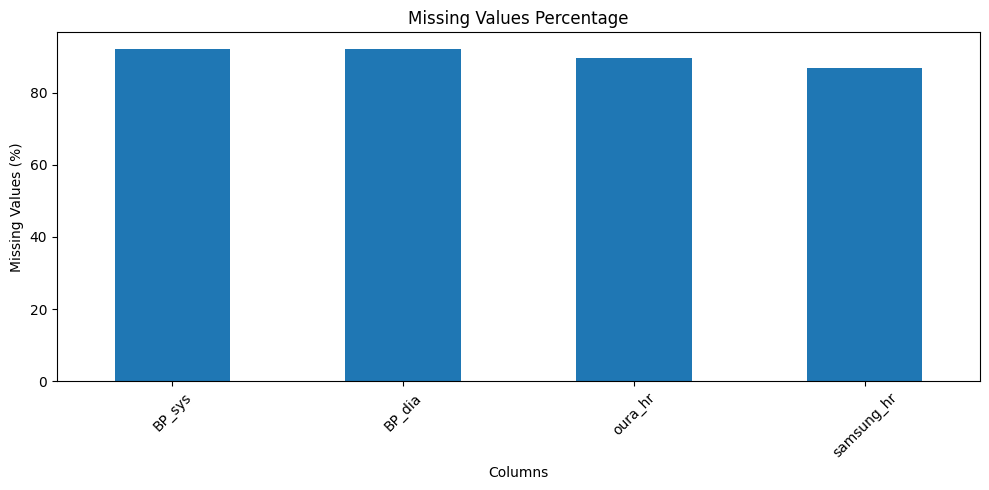

In [12]:
import matplotlib.pyplot as plt

missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent[missing_percent > 0]
missing_percent = missing_percent.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing_percent.plot(kind="bar")

plt.title("Missing Values Percentage")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

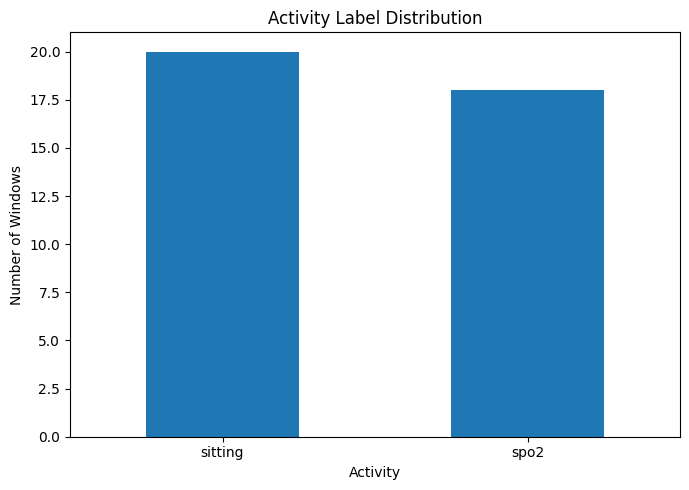

In [13]:
plt.figure(figsize=(7, 5))

df["Label"].value_counts().plot(
    kind="bar",
    rot=0
)

plt.title("Activity Label Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Windows")
plt.tight_layout()
plt.show()

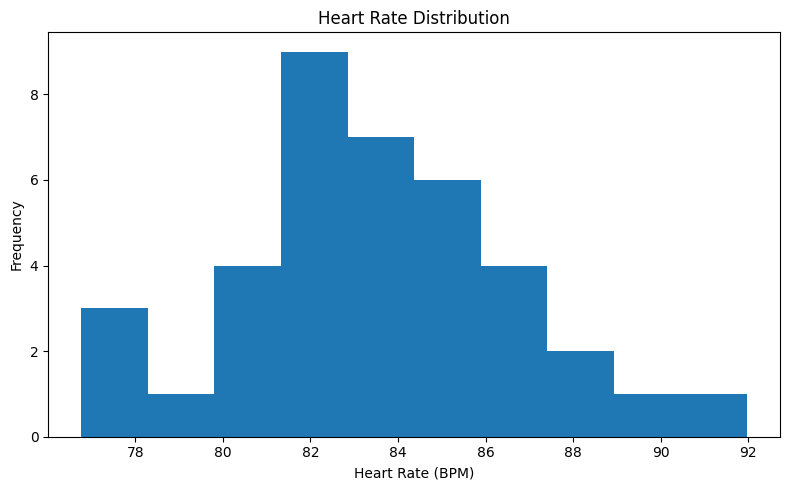

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(df["hr"].dropna(), bins=10)

plt.title("Heart Rate Distribution")
plt.xlabel("Heart Rate (BPM)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

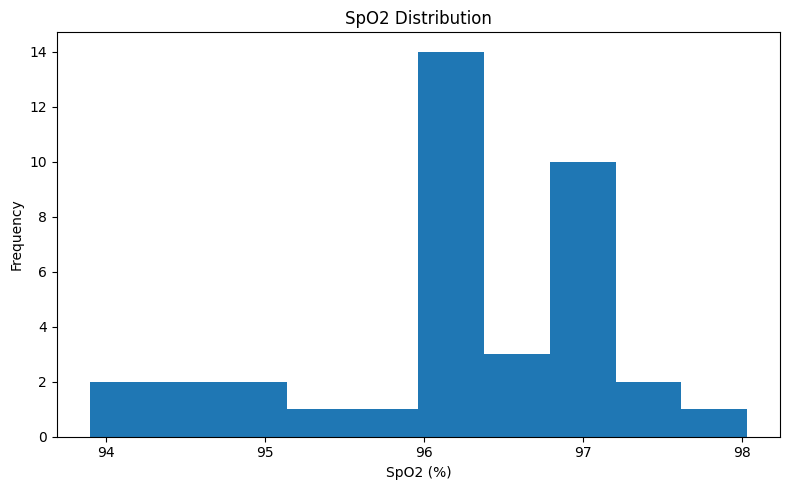

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(df["spo2"].dropna(), bins=10)

plt.title("SpO2 Distribution")
plt.xlabel("SpO2 (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Practical 1: Data Understanding — Observations and Findings

**Dataset:** HealthRing RingDatasetV2.1  
**Participant:** 00000  
**Ring:** Ring 1

1. The dataset contains 38 observations and 62 columns.
2. The columns include PPG signals, accelerometer signals, physiological measurements, timestamps and activity metadata.
3. Most signal columns are stored as object data types because they contain signal samples.
4. BP_sys and BP_dia have 92.11% missing values.
5. Oura HR has 89.47% missing values, while Samsung HR has 86.84% missing values.
6. The activity distribution consists of 20 sitting observations and 18 SpO2-labelled observations.
7. The average sampling frequency is approximately 100.33 Hz.
8. Missing values should be investigated before selecting an imputation technique.

**Conclusion:** The dataset contains both numerical measurements and array-based physiological signals. Further cleaning, type conversion, missing-value investigation and visualization are required before feature engineering.


In [19]:

import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw")

audit = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)

        # Check duplicate windows using scalar metadata only
        key_cols = [
            col for col in ["id", "start", "end"]
            if col in data.columns
        ]

        duplicate_windows = (
            data[key_cols].duplicated().sum()
            if key_cols else None
        )

        audit.append({
            "filename": file.name,
            "status": "Success",
            "rows": data.shape[0],
            "columns": data.shape[1],
            "missing_cells": int(data.isna().sum().sum()),
            "duplicate_windows": duplicate_windows,
            "error": None
        })

    except Exception as e:
        audit.append({
            "filename": file.name,
            "status": "Failed",
            "rows": None,
            "columns": None,
            "missing_cells": None,
            "duplicate_windows": None,
            "error": str(e)
        })

audit_df = pd.DataFrame(audit)

display(audit_df)


,filename,status,rows,columns,missing_cells,duplicate_windows,error
0,00000_ring1_processed.pkl,Success,38.0,62.0,137.0,0.0,None
1,00000_ring2_processed.pkl,Success,16.0,62.0,57.0,0.0,None
2,00001_ring1_processed.pkl,Success,40.0,62.0,152.0,0.0,None
3,00001_ring2_processed.pkl,Success,20.0,62.0,83.0,0.0,None
4,00002_ring1_processed.pkl,Success,79.0,62.0,355.0,0.0,None
5,00002_ring2_processed.pkl,Success,68.0,62.0,320.0,0.0,None
6,00003_ring1_processed.pkl,Success,43.0,62.0,157.0,0.0,None
7,00003_ring2_processed.pkl,Success,20.0,62.0,74.0,0.0,None
8,00004_ring1_processed.pkl,Success,45.0,62.0,232.0,0.0,None
9,00004_ring2_processed.pkl,Success,30.0,62.0,163.0,0.0,None


In [20]:

print("Total files:", len(audit_df))
print("Successfully loaded:", (audit_df["status"] == "Success").sum())
print("Failed files:", (audit_df["status"] == "Failed").sum())

display(audit_df[audit_df["status"] == "Failed"])


Total files: 57
Successfully loaded: 56
Failed files: 1


,filename,status,rows,columns,missing_cells,duplicate_windows,error
56,00029_ring2_processed.pkl,Failed,NaN,NaN,NaN,NaN,Ran out of input


In [21]:

REPORT_PATH = Path("../reports")
REPORT_PATH.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(REPORT_PATH / "data_audit.csv", index=False)

print("Corrected audit report saved!")


Corrected audit report saved!


In [22]:

failed_file = DATA_PATH / "00029_ring2_processed.pkl"

print("File exists:", failed_file.exists())

if failed_file.exists():
    print("File size:", failed_file.stat().st_size, "bytes")


File exists: True
File size: 0 bytes


In [23]:

successful = audit_df[audit_df["status"] == "Success"]

print("Total rows across successful files:",
      successful["rows"].sum())

print("Total missing cells:",
      successful["missing_cells"].sum())

print("Total duplicate windows:",
      successful["duplicate_windows"].sum())

print("Files with duplicate windows:")
display(successful[successful["duplicate_windows"] > 0])


Total rows across successful files: 3497.0
Total missing cells: 14049.0
Total duplicate windows: 0.0
Files with duplicate windows:


,filename,status,rows,columns,missing_cells,duplicate_windows,error


### Practical 2: Initial Data Quality Audit

The dataset contains 57 extracted pickle files. During the initial audit, 56 files were successfully loaded, while one file (`00029_ring2_processed.pkl`) failed to load due to a possible incomplete or corrupted pickle file.

An initial duplicate-checking error occurred because some columns contain NumPy arrays. The audit procedure was corrected to check duplicate windows using scalar metadata (`id`, `start`, and `end`) instead.

The original files were preserved without modification. The failed file will be excluded from analysis until its integrity can be investigated.

**Conclusion:** The corrected audit provides a reliable starting point for investigating missing values, duplicate windows, and data quality across the successfully loaded files.


In [24]:

from collections import defaultdict
import pandas as pd

column_missing = defaultdict(int)
column_total = defaultdict(int)

for file in sorted(DATA_PATH.glob("*.pkl")):

    try:
        data = pd.read_pickle(file)

        for col in data.columns:
            column_missing[col] += data[col].isna().sum()
            column_total[col] += len(data)

    except Exception:
        continue

missing_report = pd.DataFrame({
    "Column": list(column_missing.keys()),
    "Missing_Count": list(column_missing.values()),
    "Total_Rows": [
        column_total[col] for col in column_missing
    ]
})

missing_report["Missing_Percentage"] = (
    missing_report["Missing_Count"] /
    missing_report["Total_Rows"] * 100
)

missing_report = missing_report.sort_values(
    "Missing_Percentage", ascending=False
)

display(missing_report)


,Column,Missing_Count,Total_Rows,Missing_Percentage
59,BP_dia,3225,3497,92.221904
58,BP_sys,3225,3497,92.221904
56,samsung_hr,3150,3497,90.077209
57,oura_hr,3061,3497,87.532170
61,Label,227,3497,6.491278
...,...,...,...,...
25,ax-difference,0,3497,0.000000
26,ax-welch,0,3497,0.000000
27,ax-filtered-rr,0,3497,0.000000
28,ax-difference-rr,0,3497,0.000000


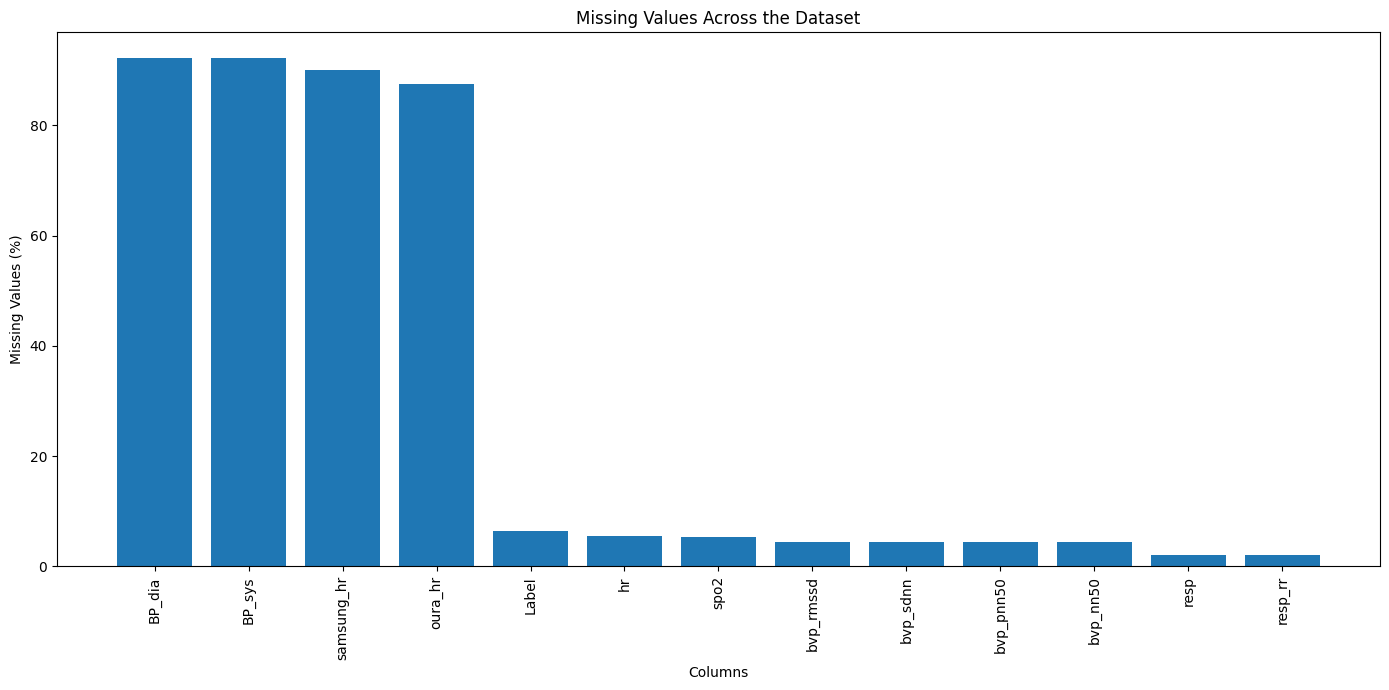

In [25]:

import matplotlib.pyplot as plt

plot_data = missing_report[
    missing_report["Missing_Count"] > 0
]

plt.figure(figsize=(14, 7))

plt.bar(
    plot_data["Column"],
    plot_data["Missing_Percentage"]
)

plt.title("Missing Values Across the Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [26]:

missing_report.to_csv(
    "../reports/missing_values_report.csv",
    index=False
)

print("Missing-value report saved successfully!")


Missing-value report saved successfully!


In [27]:

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", None)

display(
    missing_report[
        missing_report["Missing_Count"] > 0
    ].to_string(index=False)
)


'    Column  Missing_Count  Total_Rows  Missing_Percentage\n    BP_dia           3225        3497           92.221904\n    BP_sys           3225        3497           92.221904\nsamsung_hr           3150        3497           90.077209\n   oura_hr           3061        3497           87.532170\n     Label            227        3497            6.491278\n        hr            195        3497            5.576208\n      spo2            184        3497            5.261653\n bvp_rmssd            158        3497            4.518158\n  bvp_sdnn            158        3497            4.518158\n bvp_pnn50            158        3497            4.518158\n  bvp_nn50            158        3497            4.518158\n      resp             75        3497            2.144695\n   resp_rr             75        3497            2.144695'

In [28]:

file_missing = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)

        file_missing.append({
            "filename": file.name,
            "BP_sys_missing_%": data["BP_sys"].isna().mean() * 100,
            "BP_dia_missing_%": data["BP_dia"].isna().mean() * 100,
            "samsung_hr_missing_%": data["samsung_hr"].isna().mean() * 100,
            "oura_hr_missing_%": data["oura_hr"].isna().mean() * 100,
            "Label_missing_%": data["Label"].isna().mean() * 100
        })

    except Exception:
        continue

file_missing_df = pd.DataFrame(file_missing)

display(file_missing_df)


,filename,BP_sys_missing_%,BP_dia_missing_%,samsung_hr_missing_%,oura_hr_missing_%,Label_missing_%
0,00000_ring1_processed.pkl,92.105263,92.105263,86.842105,89.473684,0.000000
1,00000_ring2_processed.pkl,87.500000,87.500000,93.750000,87.500000,0.000000
2,00001_ring1_processed.pkl,100.000000,100.000000,87.500000,92.500000,0.000000
3,00001_ring2_processed.pkl,100.000000,100.000000,95.000000,95.000000,25.000000
4,00002_ring1_processed.pkl,97.468354,97.468354,97.468354,97.468354,5.063291
5,00002_ring2_processed.pkl,100.000000,100.000000,100.000000,100.000000,5.882353
6,00003_ring1_processed.pkl,90.697674,90.697674,86.046512,88.372093,0.000000
7,00003_ring2_processed.pkl,85.000000,85.000000,90.000000,100.000000,0.000000
8,00004_ring1_processed.pkl,88.888889,88.888889,82.222222,55.555556,0.000000
9,00004_ring2_processed.pkl,93.333333,93.333333,83.333333,73.333333,0.000000


### Missing Value Analysis

Missing-value analysis was performed across 56 successfully loaded pickle files containing 3,497 observations.

The analysis identified substantial missingness in several physiological measurement columns. BP_sys and BP_dia each contained 3,225 missing values (92.22%). samsung_hr contained 3,150 missing values (90.08%), while oura_hr contained 3,061 missing values (87.53%).

The Label column contained 227 missing values (6.49%).

These findings indicate that missingness varies considerably across dataset features. Automatic mean or median imputation may introduce misleading physiological measurements. Therefore, further investigation of missing-value patterns is required before selecting appropriate cleaning techniques.

The original dataset files were preserved without modification.

In [29]:

bp_check = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)

        bp_sys_missing = data["BP_sys"].isna()
        bp_dia_missing = data["BP_dia"].isna()

        bp_check.append({
            "filename": file.name,
            "BP_sys_missing": bp_sys_missing.sum(),
            "BP_dia_missing": bp_dia_missing.sum(),
            "Same_missing_pattern": bp_sys_missing.equals(
                bp_dia_missing
            ),
            "Both_available": (
                data["BP_sys"].notna() &
                data["BP_dia"].notna()
            ).sum()
        })

    except Exception:
        continue

bp_check_df = pd.DataFrame(bp_check)

display(bp_check_df)
print(
    "Files with identical BP missing patterns:",
    bp_check_df["Same_missing_pattern"].sum(),
    "out of", len(bp_check_df)
)


,filename,BP_sys_missing,BP_dia_missing,Same_missing_pattern,Both_available
0,00000_ring1_processed.pkl,35,35,True,3
1,00000_ring2_processed.pkl,14,14,True,2
2,00001_ring1_processed.pkl,40,40,True,0
3,00001_ring2_processed.pkl,20,20,True,0
4,00002_ring1_processed.pkl,77,77,True,2
5,00002_ring2_processed.pkl,68,68,True,0
6,00003_ring1_processed.pkl,39,39,True,4
7,00003_ring2_processed.pkl,17,17,True,3
8,00004_ring1_processed.pkl,40,40,True,5
9,00004_ring2_processed.pkl,28,28,True,2


Files with identical BP missing patterns: 56 out of 56


In [30]:

label_summary = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)

        label_summary.append({
            "filename": file.name,
            "total_rows": len(data),
            "missing_labels": data["Label"].isna().sum(),
            "available_labels": data["Label"].notna().sum(),
            "unique_labels": data["Label"].nunique()
        })

    except Exception:
        continue

label_summary_df = pd.DataFrame(label_summary)

display(
    label_summary_df[
        label_summary_df["missing_labels"] > 0
    ]
)


,filename,total_rows,missing_labels,available_labels,unique_labels
3,00001_ring2_processed.pkl,20,5,15,1
4,00002_ring1_processed.pkl,79,4,75,2
5,00002_ring2_processed.pkl,68,4,64,2
21,00010_ring2_processed.pkl,37,1,36,3
30,00015_ring1_processed.pkl,103,12,91,6
31,00015_ring2_processed.pkl,145,18,127,6
32,00016_ring1_processed.pkl,137,14,123,7
33,00016_ring2_processed.pkl,59,9,50,5
34,00017_ring1_processed.pkl,71,3,68,7
35,00017_ring2_processed.pkl,151,18,133,7


In [31]:

missing_label_rows = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)

        missing = data[data["Label"].isna()].copy()

        if not missing.empty:
            missing["source_file"] = file.name

            columns = [
                "source_file", "id", "start", "end",
                "Experiment", "Label"
            ]

            missing_label_rows.append(missing[columns])

    except Exception:
        continue

if missing_label_rows:
    missing_labels_df = pd.concat(
        missing_label_rows,
        ignore_index=True
    )

    print("Total missing-label rows:",
          len(missing_labels_df))

    display(missing_labels_df.head(20))


Total missing-label rows: 227


,source_file,id,start,end,Experiment,Label
0,00001_ring2_processed.pkl,15,1.742458e+09,1.742458e+09,Health,None
1,00001_ring2_processed.pkl,16,1.742458e+09,1.742458e+09,Health,None
2,00001_ring2_processed.pkl,17,1.742458e+09,1.742458e+09,Health,None
3,00001_ring2_processed.pkl,18,1.742458e+09,1.742458e+09,Health,None
4,00001_ring2_processed.pkl,19,1.742458e+09,1.742458e+09,Health,None
5,00002_ring1_processed.pkl,14,1.742992e+09,1.742992e+09,Daily,None
6,00002_ring1_processed.pkl,15,1.742992e+09,1.742992e+09,Daily,None
7,00002_ring1_processed.pkl,16,1.742992e+09,1.742992e+09,Daily,None
8,00002_ring1_processed.pkl,17,1.742992e+09,1.742992e+09,Daily,None
9,00002_ring2_processed.pkl,2,1.742992e+09,1.742992e+09,Daily,None


In [32]:

all_labels = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)
        all_labels.append(data[["Experiment", "Label"]])
    except Exception:
        continue

labels_df = pd.concat(all_labels, ignore_index=True)

print("Activity label distribution:")
display(labels_df["Label"].value_counts(dropna=False))

print("Experiment distribution:")
display(labels_df["Experiment"].value_counts(dropna=False))

print("Labels by experiment:")
display(pd.crosstab(
    labels_df["Experiment"],
    labels_df["Label"],
    dropna=False
))


Activity label distribution:


Label
sitting         1770
spo2             812
deepsquat        274
None             227
talking          116
shaking_head      99
standing          85
striding          70
sync              44
Name: count, dtype: int64

Experiment distribution:


Experiment
Health    1980
Daily     1517
Name: count, dtype: int64

Labels by experiment:


Label,deepsquat,shaking_head,sitting,spo2,standing,striding,sync,talking,NaN
Experiment,,,,,,,,,
Daily,0,99,882,0,85,70,44,116,221
Health,274,0,888,812,0,0,0,0,6


In [33]:

missing_pattern = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file).copy()
        missing = data[data["Label"].isna()]

        if not missing.empty:
            missing_pattern.append({
                "filename": file.name,
                "missing_rows": len(missing),
                "first_missing_id": missing["id"].min(),
                "last_missing_id": missing["id"].max(),
                "missing_experiments": ", ".join(
                    missing["Experiment"].dropna().unique()
                )
            })

    except Exception:
        continue

missing_pattern_df = pd.DataFrame(missing_pattern)

display(missing_pattern_df)


,filename,missing_rows,first_missing_id,last_missing_id,missing_experiments
0,00001_ring2_processed.pkl,5,15,19,Health
1,00002_ring1_processed.pkl,4,14,17,Daily
2,00002_ring2_processed.pkl,4,2,5,Daily
3,00010_ring2_processed.pkl,1,8,8,Health
4,00015_ring1_processed.pkl,12,43,101,Daily
5,00015_ring2_processed.pkl,18,20,134,Daily
6,00016_ring1_processed.pkl,14,43,132,Daily
7,00016_ring2_processed.pkl,9,32,51,Daily
8,00017_ring1_processed.pkl,3,45,48,Daily
9,00017_ring2_processed.pkl,18,35,114,Daily


### Activity Label Analysis

The combined dataset contains 3,497 observations across two experiment categories: Health (1,980 observations) and Daily (1,517 observations).

The activity-label distribution is:

- Sitting: 1,770
- SpO2: 812
- Deepsquat: 274
- Talking: 116
- Shaking_head: 99
- Standing: 85
- Striding: 70
- Sync: 44
- Missing: 227

The cross-tabulation indicates that activity labels differ between the Health and Daily experiments. The Health experiment contains deepsquat, sitting and spo2 labels, while the Daily experiment contains shaking_head, sitting, standing, striding, sync and talking labels.

A total of 227 observations (6.49%) have missing activity labels. These values will be preserved as missing rather than replaced with guessed labels, because doing so could introduce incorrect ground-truth information.

The numerical SpO2 measurement and the categorical `spo2` activity label are treated as separate variables.

In [34]:

def find_missing_runs(ids):
    ids = sorted(set(ids))

    if not ids:
        return []

    runs = []
    start = previous = ids[0]

    for current in ids[1:]:
        if current == previous + 1:
            previous = current
        else:
            runs.append((start, previous))
            start = previous = current

    runs.append((start, previous))
    return runs


label_runs = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)
        missing_ids = data.loc[
            data["Label"].isna(), "id"
        ].dropna().astype(int).tolist()

        if missing_ids:
            label_runs.append({
                "filename": file.name,
                "missing_ids": sorted(missing_ids),
                "continuous_runs": find_missing_runs(missing_ids)
            })

    except Exception:
        continue

label_runs_df = pd.DataFrame(label_runs)
display(label_runs_df)


,filename,missing_ids,continuous_runs
0,00001_ring2_processed.pkl,"[15, 16, 17, 18, 19]","[(15, 19)]"
1,00002_ring1_processed.pkl,"[14, 15, 16, 17]","[(14, 17)]"
2,00002_ring2_processed.pkl,"[2, 3, 4, 5]","[(2, 5)]"
3,00010_ring2_processed.pkl,[8],"[(8, 8)]"
4,00015_ring1_processed.pkl,"[43, 45, 46, 47, 48, 49, 85, 86, 87, 88, 89, 101]","[(43, 43), (45, 49), (85, 89), (101, 101)]"
5,00015_ring2_processed.pkl,"[20, 22, 23, 24, 25, 26, 89, 90, 91, 93, 94, 9...","[(20, 20), (22, 26), (89, 91), (93, 97), (109,..."
6,00016_ring1_processed.pkl,"[43, 46, 47, 48, 49, 90, 91, 92, 103, 106, 107...","[(43, 43), (46, 49), (90, 92), (103, 103), (10..."
7,00016_ring2_processed.pkl,"[32, 35, 36, 37, 38, 46, 49, 50, 51]","[(32, 32), (35, 38), (46, 46), (49, 51)]"
8,00017_ring1_processed.pkl,"[45, 47, 48]","[(45, 45), (47, 48)]"
9,00017_ring2_processed.pkl,"[35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 4...","[(35, 49), (111, 111), (113, 114)]"


In [35]:

numeric_columns = [
    "hr",
    "bvp_hr",
    "bvp_sdnn",
    "bvp_rmssd",
    "bvp_nn50",
    "bvp_pnn50",
    "resp_rr",
    "spo2",
    "samsung_hr",
    "oura_hr",
    "BP_sys",
    "BP_dia"
]

all_measurements = []

for file in sorted(DATA_PATH.glob("*.pkl")):
    try:
        data = pd.read_pickle(file)

        available = [
            col for col in numeric_columns
            if col in data.columns
        ]

        temp = data[available].copy()
        temp["source_file"] = file.name

        for col in available:
            temp[col] = pd.to_numeric(
                temp[col], errors="coerce"
            )

        all_measurements.append(temp)

    except Exception:
        continue

measurements_df = pd.concat(
    all_measurements, ignore_index=True
)

display(measurements_df[numeric_columns].describe().T)


,count,mean,std,min,25%,50%,75%,max
hr,3302.0,81.359147,12.637242,40.000000,72.775000,80.466667,88.533333,125.933333
bvp_hr,3497.0,77.192907,19.776521,30.000957,69.050190,78.369382,88.031236,177.108789
bvp_sdnn,3339.0,0.109976,0.068330,0.018677,0.043777,0.104589,0.162115,0.525518
bvp_rmssd,3339.0,0.130306,0.085034,0.028659,0.052768,0.114790,0.189567,0.743195
bvp_nn50,3339.0,16.568134,16.247535,0.000000,5.000000,10.000000,23.000000,89.000000
bvp_pnn50,3339.0,34.077696,26.500266,0.000000,13.157895,26.190476,48.547980,98.888889
resp_rr,3422.0,17.603663,4.555388,6.039162,15.252687,18.230108,19.928769,29.864390
spo2,3313.0,96.255173,2.658184,78.966667,96.000000,97.000000,97.900000,99.000000
samsung_hr,347.0,92.282421,23.094573,50.000000,77.000000,87.000000,103.000000,170.000000
oura_hr,436.0,89.672018,22.319318,36.000000,73.000000,85.000000,100.000000,155.000000
